In [2]:
%matplotlib widget

import json
import matplotlib.pyplot as plt
from ipywidgets import Text, Button, HBox, Label
from IPython.disply import display

ModuleNotFoundError: No module named 'IPython.disply'

Label(value='Pronto.')

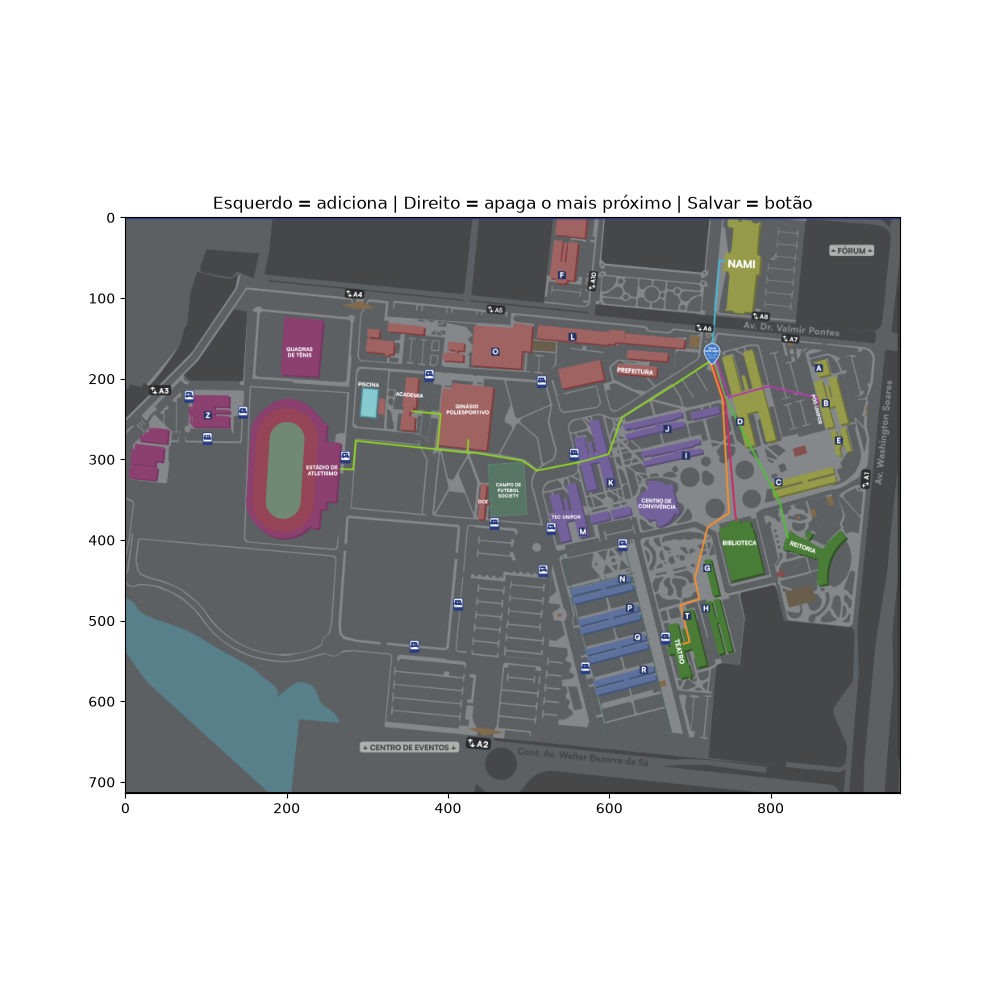

In [3]:
img = plt.imread("./data/map.png")
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
ax.set_title("Esquerdo = adiciona | Direito = apaga o mais próximo | Salvar = botão")

vertices = {}   # label -> (x, y)
artistas = {}   # label -> (dot, texto) para poder remover do plot

# --- widgets de UI ---
nome = Text(placeholder="Nome do vértice (vazio = automático: v0, v1, ...)")
status = Label(value="Pronto.")
btn_salvar = Button(description="Salvar", button_style="success")
display(HBox([nome, btn_salvar]), status)

def proximo_vertice(x, y, raio=15):
    """Retorna o label do vértice mais próximo dentro do raio (em pixels), ou None."""
    melhor, dmin = None, None
    for label, (vx, vy) in vertices.items():
        d = ((x - vx) ** 2 + (y - vy) ** 2) ** 0.5
        if dmin is None or d < dmin:
            melhor, dmin = label, d
    if melhor is not None and dmin <= raio:
        return melhor
    return None

def remover_vertice(label):
    dot, texto = artistas.pop(label)
    dot.remove()
    texto.remove()
    del vertices[label]
    status.value = f"Removido: {label}"
    fig.canvas.draw_idle()

def on_click(event):
    if event.inaxes is not ax:
        return
    if event.button == 1:                       # esquerdo: adiciona
        label = nome.value.strip() or f"v{len(vertices)}"
        while label in vertices:                # evita duplicado
            label += "_"
        vertices[label] = (event.xdata, event.ydata)
        dot, = ax.plot(*vertices[label], "ro")
        texto = ax.annotate(label, vertices[label], xytext=(6, 6),
                            textcoords="offset points", color="yellow")
        artistas[label] = (dot, texto)
        nome.value = ""                        # limpa para o próximo
        status.value = f"Adicionado: {label} ({len(vertices)} no total)"
    elif event.button == 3:                    # direito: apaga o mais próximo
        label = proximo_vertice(event.xdata, event.ydata)
        if label:
            remover_vertice(label)
        else:
            status.value = "Nenhum vértice próximo para remover."
    fig.canvas.draw_idle()

def salvar(_=None):
    json.dump({k: list(v) for k, v in vertices.items()}, open("vertices.json", "w"))
    status.value = f"{len(vertices)} vértices salvos em vertices.json"
    fig.canvas.mpl_disconnect(cid_click)

btn_salvar.on_click(salvar)
cid_click = fig.canvas.mpl_connect("button_press_event", on_click)